In [ ]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

def load_dataset():
    if 'google.colab' in sys.modules:
        from google.colab import files
        import io
        print("Running in Google Colab — please upload facility_reservations.csv ...")
        uploaded = files.upload()
        filename = list(uploaded.keys())[0]
        df = pd.read_csv(io.BytesIO(uploaded[filename]))
        print(f"Uploaded file: {filename}")
    else:
        try:
            df = pd.read_csv('facility_reservations.csv')
            print("Loaded local file: facility_reservations.csv")
        except FileNotFoundError:
            print("ERROR: facility_reservations.csv not found.")
            raise
    return df

df = load_dataset()
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Running in Google Colab — please upload facility_reservations.csv ...


In [ ]:
# ============================================================
# PART IV – Data Mining and Predictive Modeling
# ============================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ------------------------------------------------------------
# 0. Create a realistic synthetic dataset (REPLACE THIS BLOCK
#    with pd.read_csv('facility_reservations.csv') when you have the real file)
# ------------------------------------------------------------
np.random.seed(42)
n = 450

facility_types = ['Classroom', 'Auditorium', 'Laboratory', 'Gym', 'Conference Room']
user_categories = ['Student', 'Faculty', 'Staff', 'External']
usage_status = ['Used', 'Cancelled', 'No-Show']

df = pd.DataFrame({
    'Reservation_ID': [f'R{1000+i}' for i in range(n)],
    'Facility_Type': np.random.choice(facility_types, n, p=[0.35, 0.15, 0.20, 0.15, 0.15]),
    'User_Category': np.random.choice(user_categories, n, p=[0.55, 0.25, 0.15, 0.05]),
    'Participants': np.random.randint(5, 120, n),
    'Lead_Time_Days': np.random.randint(0, 45, n),
    'Reservation_Date': pd.date_range('2025-01-01', periods=n, freq='D'),
    'Usage_Status': np.random.choice(usage_status, n, p=[0.68, 0.22, 0.10]),
    'Actual_Attendance': np.nan,          # will fill later
    'Cancellation_Days_Before': np.nan
})

# Realistic attendance & cancellation logic
for i in range(n):
    if df.loc[i, 'Usage_Status'] == 'Used':
        df.loc[i, 'Actual_Attendance'] = max(1, int(df.loc[i, 'Participants'] * np.random.uniform(0.55, 1.05)))
    elif df.loc[i, 'Usage_Status'] == 'Cancelled':
        df.loc[i, 'Cancellation_Days_Before'] = np.random.randint(0, max(1, df.loc[i, 'Lead_Time_Days']))
    # introduce a few missing values / inconsistencies as required by the exam
df.loc[np.random.choice(n, 12, replace=False), 'Participants'] = np.nan
df.loc[np.random.choice(n, 8, replace=False), 'Lead_Time_Days'] = -3   # invalid
df.loc[np.random.choice(n, 5, replace=False), 'Facility_Type'] = 'classroom'  # case inconsistency
df = pd.concat([df, df.iloc[[10, 25, 40]]], ignore_index=True)  # duplicates

print("Raw shape:", df.shape)

# ------------------------------------------------------------
# 1. Cleaning (mirrors Part II – needed before modelling)
# ------------------------------------------------------------
df_clean = df.copy()

# Missing Participants → median by Facility_Type
df_clean['Participants'] = df_clean.groupby('Facility_Type')['Participants']\
                                   .transform(lambda x: x.fillna(x.median()))

# Invalid Lead_Time_Days → set to NaN then median
df_clean.loc[df_clean['Lead_Time_Days'] < 0, 'Lead_Time_Days'] = np.nan
df_clean['Lead_Time_Days'] = df_clean['Lead_Time_Days'].fillna(
    df_clean['Lead_Time_Days'].median()).astype(int)

# Standardise Facility_Type
df_clean['Facility_Type'] = df_clean['Facility_Type'].str.title()

# Drop exact duplicates
df_clean = df_clean.drop_duplicates(subset=['Reservation_ID'], keep='first')

# Derived variables (Part II Task 5)
def lead_cat(x):
    if x <= 2: return 'Last Minute'
    elif x <= 7: return 'Short Lead'
    elif x <= 14: return 'Medium Lead'
    else: return 'Early Booking'

df_clean['Lead_Time_Category'] = df_clean['Lead_Time_Days'].apply(lead_cat)

df_clean['Reservation_Outcome'] = df_clean['Usage_Status'].map(
    {'Used': 'Completed', 'Cancelled': 'Not Completed', 'No-Show': 'Not Completed'}
)

df_clean['Attendance_Ratio'] = np.where(
    (df_clean['Participants'].isna()) | (df_clean['Participants'] == 0),
    np.nan,
    df_clean['Actual_Attendance'] / df_clean['Participants']
)

print("Clean shape:", df_clean.shape)
print(df_clean['Reservation_Outcome'].value_counts())

# ------------------------------------------------------------
# 2. Feature selection – STRICTLY no leakage
# ------------------------------------------------------------
# Predictors available at reservation submission time only
features = [
    'Facility_Type',          # categorical
    'User_Category',          # categorical
    'Participants',           # numerical
    'Lead_Time_Days',         # numerical
    'Lead_Time_Category'      # categorical (derived from Lead_Time_Days)
]

target = 'Reservation_Outcome'

# Explicitly excluded (post-outcome / leakage):
# Usage_Status, Actual_Attendance, Cancellation_Days_Before, Attendance_Ratio

X = df_clean[features].copy()
y = df_clean[target].copy()

# Encode categoricals
le_dict = {}
for col in ['Facility_Type', 'User_Category', 'Lead_Time_Category']:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    le_dict[col] = le

# Encode target
le_y = LabelEncoder()
y_enc = le_y.fit_transform(y)   # Completed=0, Not Completed=1 (or vice-versa)

# ------------------------------------------------------------
# 3. Train / Test split (80/20) + fixed random_state
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.20, random_state=42, stratify=y_enc
)

print(f"Train size: {len(X_train)}  |  Test size: {len(X_test)}")
print("Class distribution (train):", np.bincount(y_train))
print("Class distribution (test):",  np.bincount(y_test))

# ------------------------------------------------------------
# 4. Decision Tree Classifier
# ------------------------------------------------------------
clf = DecisionTreeClassifier(
    max_depth=5,          # keep interpretable
    min_samples_leaf=10,
    random_state=42
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

# ------------------------------------------------------------
# 5. Evaluation metrics
# ------------------------------------------------------------
print("\n===== CONFUSION MATRIX =====")
cm = confusion_matrix(y_test, y_pred)
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=le_y.classes_)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix – Reservation_Outcome")
plt.show()

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"\nAccuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

print("\n===== Classification Report =====")
print(classification_report(y_test, y_pred, target_names=le_y.classes_, zero_division=0))

# ------------------------------------------------------------
# 6. Feature importance – top 3 predictors
# ------------------------------------------------------------
importances = pd.Series(clf.feature_importances_, index=features)\
                .sort_values(ascending=False)
print("\n===== FEATURE IMPORTANCE =====")
print(importances)

print("\nThree most influential predictors:")
for i, (feat, imp) in enumerate(importances.head(3).items(), 1):
    print(f"  {i}. {feat}  (importance = {imp:.4f})")

# Optional: visualise the tree
plt.figure(figsize=(18, 8))
plot_tree(clf, feature_names=features, class_names=le_y.classes_,
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree – Reservation Outcome")
plt.show()

# ------------------------------------------------------------
# 7. Leakage explanation (required by the exam)
# ------------------------------------------------------------
print("""
LEAKAGE AVOIDANCE:
- Predictors were restricted to information known at the moment a reservation is submitted:
  Facility_Type, User_Category, Participants, Lead_Time_Days, Lead_Time_Category.
- The following post-outcome fields were deliberately excluded:
  Usage_Status, Actual_Attendance, Cancellation_Days_Before, Attendance_Ratio.
- Therefore the model cannot “see” the true outcome and cannot leak information.
""")

In [ ]:
# Task 1
print("=" * 60)
print("FIRST 10 RECORDS")
print("=" * 60)
display(df.head(10))

print("\n" + "=" * 60)
print("NUMBER OF ROWS AND COLUMNS")
print("=" * 60)
print(f"Rows: {df.shape[0]}   |   Columns: {df.shape[1]}")

print("\n" + "=" * 60)
print("VARIABLE TYPES (dtypes)")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("SUMMARY STATISTICS (numerical)")
print("=" * 60)
display(df.describe())

print("\n" + "=" * 60)
print("SUMMARY STATISTICS (categorical / object)")
print("=" * 60)
display(df.describe(include='object'))

FIRST 10 RECORDS


,Reservation_ID,User_Type,Facility_Type,Reservation_Date,Event_Date,Start_Time,End_Time,Duration_Hours,Participants,Purpose,Approval_Status,Days_Before_Event,After_Office_Hours,Actual_Attendance,Usage_Status,Cancellation_Days_Before
0,RES-0001,Faculty,Classroom,2026-01-10,2026-01-10,09:00,10:00,1,52,Meeting,Approved,0,No,0,No-Show,NaN
1,RES-0002,Faculty,Gymnasium,2026-06-21,2026-07-09,17:00,19:00,2,110,Seminar,Approved,18,Yes,108,Used,NaN
2,RES-0003,Faculty,Conference Room,2026-04-19,2026-04-25,09:00,10:00,1,35,Event,Approved,6,No,0,Cancelled,6.0
3,RES-0004,Staff,Gymnasium,2026-04-21,2026-06-14,10:00,11:00,1,20,Class,Approved,54,No,16,Used,NaN
4,RES-0005,Staff,Classroom,2026-08-26,2026-08-30,16:00,20:00,4,18,Meeting,Approved,4,Yes,13,Used,NaN
5,RES-0006,Staff,Auditorium,2026-02-13,2026-02-16,08:00,13:00,5,168,Class,Approved,3,No,134,Used,NaN
6,RES-0007,Student,Laboratory,2026-07-08,2026-07-09,15:00,16:00,1,158,Organization Activity,Approved,1,No,117,Used,NaN
7,RES-0008,Faculty,Gymnasium,2026-05-09,2026-05-17,17:00,18:00,1,166,Meeting,Approved,8,Yes,114,Used,NaN
8,RES-0009,Faculty,Laboratory,2026-08-09,2026-10-07,09:00,13:00,4,94,Organization Activity,Approved,59,No,69,Used,NaN
9,RES-0010,Faculty,Multimedia Room,2026-03-04,2026-03-04,10:00,11:00,1,108,Class,Approved,0,No,79,Used,NaN



NUMBER OF ROWS AND COLUMNS
Rows: 400   |   Columns: 16

VARIABLE TYPES (dtypes)
Reservation_ID               object
User_Type                    object
Facility_Type                object
Reservation_Date             object
Event_Date                   object
Start_Time                   object
End_Time                     object
Duration_Hours                int64
Participants                  int64
Purpose                      object
Approval_Status              object
Days_Before_Event             int64
After_Office_Hours           object
Actual_Attendance             int64
Usage_Status                 object
Cancellation_Days_Before    float64
dtype: object

SUMMARY STATISTICS (numerical)


,Duration_Hours,Participants,Days_Before_Event,Actual_Attendance,Cancellation_Days_Before
count,400.000000,400.000000,400.000000,400.000000,14.000000
mean,2.500000,100.557500,12.267500,74.115000,4.357143
std,1.270447,55.412752,13.164696,51.162739,7.217576
min,1.000000,10.000000,0.000000,0.000000,0.000000
25%,2.000000,51.000000,4.000000,27.000000,0.000000
50%,2.000000,104.000000,8.000000,70.000000,1.500000
75%,3.000000,149.250000,13.000000,117.000000,5.500000
max,5.000000,200.000000,59.000000,188.000000,26.000000



SUMMARY STATISTICS (categorical / object)


,Reservation_ID,User_Type,Facility_Type,Reservation_Date,Event_Date,Start_Time,End_Time,Purpose,Approval_Status,After_Office_Hours,Usage_Status
count,400,400,400,400,400,400,400,400,400,400,400
unique,400,4,6,189,201,11,13,7,2,2,3
top,RES-0384,Student,Laboratory,2026-01-19,2026-01-25,16:00,20:00,Class,Approved,No,Used
freq,1,107,76,6,6,46,60,67,393,261,359


In [ ]:

# ============================================================
# PART VI — DECISION SUPPORT AND CRITICAL ANALYSIS
# Campus Facility Reservation and Monitoring System
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# 1. LOAD THE CLEANED DATASET
df = pd.read_csv("facility_reservations_cleaned.csv")

# Standardize column names
df.columns = df.columns.str.strip()

required = [
    "Facility_Type", "User_Category",
    "Usage_Status", "Reservation_Outcome",
    "Lead_Time_Category"
]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(
        f"Missing required columns: {missing}. "
        "Check your CSV column names."
    )

# 2. CALCULATE OBSERVED STATISTICS
total_reservations = len(df)

completed = (
    df["Reservation_Outcome"] == "Completed"
).sum()

not_completed = (
    df["Reservation_Outcome"] == "Not Completed"
).sum()

known_outcomes = df["Reservation_Outcome"].notna().sum()

completion_rate = (
    completed / known_outcomes * 100
    if known_outcomes else 0
)

not_completed_rate = (
    not_completed / known_outcomes * 100
    if known_outcomes else 0
)

display(Markdown("# Campus Facility Reservation Dashboard"))
display(Markdown(
    "**Observed statistics** come from recorded data. "
    "**Predicted risk** comes from the machine-learning model."
))

# KPI summary
kpi = pd.DataFrame({
    "Measure": [
        "Total Reservations",
        "Completed Reservations",
        "Cancelled / No-Show",
        "Completion Rate",
        "Not Completed Rate"
    ],
    "Value": [
        total_reservations,
        int(completed),
        int(not_completed),
        f"{completion_rate:.1f}%",
        f"{not_completed_rate:.1f}%"
    ]
})

display(kpi)

# 3. OBSERVED RESERVATIONS BY FACILITY TYPE
facility_counts = df["Facility_Type"].value_counts()

plt.figure(figsize=(8, 4))
facility_counts.plot(kind="bar")
plt.title("Reservations by Facility Type (Observed)")
plt.xlabel("Facility Type")
plt.ylabel("Number of Reservations")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 4. OBSERVED CANCELLATION / NO-SHOW RATE BY USER CATEGORY
status = df["Usage_Status"].astype("string").str.strip().str.lower()

cancelled_statuses = ["cancelled", "canceled", "no-show", "noshow"]
valid_statuses = [
    "used", "completed", "cancelled", "canceled",
    "no-show", "noshow"
]

status_df = df[status.isin(valid_statuses)].copy()
status_df["_status"] = status[status.isin(valid_statuses)]

status_df["_not_completed"] = status_df["_status"].isin(
    cancelled_statuses
)

if len(status_df):
    cancellation_rates = (
        status_df.groupby("User_Category")["_not_completed"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(8, 4))
    cancellation_rates.plot(kind="bar")
    plt.title("Cancellation / No-Show Rate by User Category (Observed)")
    plt.xlabel("User Category")
    plt.ylabel("Cancellation / No-Show Rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    display(cancellation_rates.rename(
        "Cancellation / No-Show Rate (%)"
    ).round(2).to_frame())
else:
    print("No recognized reservation statuses were found.")

# 5. OBSERVED OUTCOME BY LEAD-TIME CATEGORY
lead_order = [
    "Last Minute", "Short Lead",
    "Medium Lead", "Early Booking"
]

outcome_table = pd.crosstab(
    df["Lead_Time_Category"],
    df["Reservation_Outcome"],
    normalize="index"
).mul(100)

outcome_table = outcome_table.reindex(lead_order).dropna(how="all")

if not outcome_table.empty:
    outcome_table.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 4)
    )
    plt.title("Reservation Outcome by Lead-Time Category (Observed)")
    plt.xlabel("Lead-Time Category")
    plt.ylabel("Percentage (%)")
    plt.xticks(rotation=20, ha="right")
    plt.legend(title="Observed Outcome")
    plt.tight_layout()
    plt.show()

    display(outcome_table.round(2))

# ============================================================
# 6. PREDICTED RISK LEVELS USING A DECISION TREE
# ============================================================

# Only use fields available when a reservation is submitted.
candidate_features = [
    "Facility_Type",
    "User_Category",
    "Participants",
    "Lead_Time_Days",
    "Lead_Time_Category",
    "Reservation_Type",
    "Facility_Location",
    "Start_Time",
    "Duration_Hours"
]

features = [c for c in candidate_features if c in df.columns]
target = "Reservation_Outcome"

model_data = df[df[target].isin(
    ["Completed", "Not Completed"]
)].copy()

if len(features) < 5:
    print(
        "Risk prediction skipped: fewer than five eligible predictor "
        "columns are available. Check the CSV and Part IV features."
    )
elif model_data[target].nunique() < 2:
    print(
        "Risk prediction skipped: the dataset needs both Completed "
        "and Not Completed outcomes."
    )
else:
    X = model_data[features].copy()
    y = model_data[target].copy()

    # Convert date/time fields to usable text categories when present
    for col in X.columns:
        if (
            pd.api.types.is_object_dtype(X[col])
            or pd.api.types.is_string_dtype(X[col])
        ):
            X[col] = X[col].astype("string").fillna("Unknown")

    numeric_features = X.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_features = [
        c for c in X.columns if c not in numeric_features
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocess = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    model = Pipeline([
        ("preprocess", preprocess),
        ("tree", DecisionTreeClassifier(
            max_depth=5,
            class_weight="balanced",
            random_state=42
        ))
    ])

    # Use a holdout test split when possible
    try:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, random_state=42,
            stratify=y
        )
    except ValueError:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, random_state=42
        )

    model.fit(X_train, y_train)

    # These predictions are for model demonstration/evaluation.
    # They are NOT actual future outcomes.
    probabilities = model.predict_proba(X)
    classes = model.named_steps["tree"].classes_

    not_completed_index = list(classes).index("Not Completed")
    risk_probability = probabilities[:, not_completed_index] * 100

    risk_level = np.select(
        [risk_probability >= 70, risk_probability >= 40],
        ["High", "Medium"],
        default="Low"
    )

    risk_table = pd.DataFrame({
        "Record": model_data.index,
        "Facility Type": (
            model_data["Facility_Type"].values
        ),
        "User Category": (
            model_data["User_Category"].values
        ),
        "Predicted Risk (%)": risk_probability.round(1),
        "Predicted Risk Level": risk_level,
        "Observed Outcome": model_data[target].values
    })

    display(Markdown(
        "## Predicted Risk Levels\n"
        "**Predictions are model estimates, not confirmed outcomes.** "
        "These rows represent existing records, not necessarily "
        "upcoming reservations."
    ))

    display(
        risk_table.sort_values(
            "Predicted Risk (%)", ascending=False
        ).head(10)
    )

    # Risk-level chart
    risk_counts = risk_table["Predicted Risk Level"].value_counts()
    risk_counts = risk_counts.reindex(
        ["High", "Medium", "Low"], fill_value=0
    )

    plt.figure(figsize=(6, 4))
    risk_counts.plot(kind="bar")
    plt.title("Model-Predicted Risk Levels")
    plt.xlabel("Predicted Risk Level")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ============================================================
# 7. TASK 12 — SHORT WRITTEN ANSWERS
# ============================================================

display(Markdown("""
## Task 12 — Short Answers

**(a) Why should predicted high risk not automatically reject a reservation?**

A high-risk prediction is only an estimate, not a guarantee that the
reservation will fail. Automatic rejection may unfairly affect users,
so staff should review the prediction and make the final decision.

**(b) How does poor data quality affect the model and information system?**

Missing values, duplicate records, incorrect categories, and invalid
numbers can produce inaccurate or biased predictions. They can also
make reports unreliable and lead to poor facility-management decisions.

**(c) What information should be displayed to explain a high-risk prediction?**

Display the predicted risk level and probability, the main factors that
influenced the prediction, relevant patterns from similar historical
reservations, and recommended actions such as verifying details or
contacting the user. Clearly label predictions separately from observed
historical outcomes.
"""))


In [ ]:
# Task 2
print("""
DATA DICTIONARY / VARIABLE ROLES
================================

TARGET VARIABLE:
  • Reservation_Outcome  (will be derived in Part II)
    Role: Binary classification target.
          "Completed" if Usage_Status = Used;
          "Not Completed" if Cancelled or No-Show.

FIVE PREDICTOR CANDIDATES (available at reservation submission time):
  1. Facility_Type
  2. User_Category
  3. Lead_Time_Days
  4. Participants
  5. Reservation_Method
  (Duration_Hours can also be used)

TWO CATEGORICAL VARIABLES:
  • Facility_Type
  • User_Category

TWO NUMERICAL VARIABLES:
  • Lead_Time_Days
  • Participants
""")


DATA DICTIONARY / VARIABLE ROLES

TARGET VARIABLE:
  • Reservation_Outcome  (will be derived in Part II)
    Role: Binary classification target.
          "Completed" if Usage_Status = Used;
          "Not Completed" if Cancelled or No-Show.

FIVE PREDICTOR CANDIDATES (available at reservation submission time):
  1. Facility_Type
  2. User_Category
  3. Lead_Time_Days
  4. Participants
  5. Reservation_Method
  (Duration_Hours can also be used)

TWO CATEGORICAL VARIABLES:
  • Facility_Type
  • User_Category

TWO NUMERICAL VARIABLES:
  • Lead_Time_Days
  • Participants



In [ ]:
# Task 3
print("""
DATA ACQUISITION FROM THE LIVE UNIVERSITY SYSTEM
================================================

Option A – REST API:
  GET /api/v1/reservations?start_date=2024-01-01&end_date=2024-12-31
  Headers: Authorization: Bearer <token>

Option B – SQL:
  SELECT r.reservation_id, f.facility_type, u.user_category,
         r.reservation_date, r.event_date, r.lead_time_days,
         r.participants, r.actual_attendance, r.usage_status,
         r.cancellation_days_before, r.reservation_method, r.duration_hours
  FROM reservations r
  JOIN facilities f ON r.facility_id = f.facility_id
  JOIN users u ON r.user_id = u.user_id
  WHERE r.reservation_date BETWEEN '2024-01-01' AND '2024-12-31';

ONE VALIDATION CHECK DURING COLLECTION:
  Ensure Event_Date >= Reservation_Date (Lead_Time_Days >= 0)
  and Participants > 0.
""")


DATA ACQUISITION FROM THE LIVE UNIVERSITY SYSTEM

Option A – REST API:
  GET /api/v1/reservations?start_date=2024-01-01&end_date=2024-12-31
  Headers: Authorization: Bearer <token>

Option B – SQL:
  SELECT r.reservation_id, f.facility_type, u.user_category,
         r.reservation_date, r.event_date, r.lead_time_days,
         r.participants, r.actual_attendance, r.usage_status,
         r.cancellation_days_before, r.reservation_method, r.duration_hours
  FROM reservations r
  JOIN facilities f ON r.facility_id = f.facility_id
  JOIN users u ON r.user_id = u.user_id
  WHERE r.reservation_date BETWEEN '2024-01-01' AND '2024-12-31';

ONE VALIDATION CHECK DURING COLLECTION:
  Ensure Event_Date >= Reservation_Date (Lead_Time_Days >= 0)
  and Participants > 0.



In [ ]:
import os
import pandas as pd
import numpy as np

# ============================================================
# TASK 5: DERIVED VARIABLES & ROBUST CLEANING RECOVERY
# ============================================================

try:
    # Try to access global 'df'
    if 'df' in globals():
        working_df = df.copy()
        print("Successfully loaded 'df' from memory.")
    else:
        # Fallback: Reload from raw uploaded files in local directory
        raw_files = [f for f in os.listdir('.') if f.startswith('facility_reservations') and f.endswith('.csv')]
        if not raw_files:
            raise FileNotFoundError(
                "The raw dataset could not be found. Please scroll to the top "
                "and re-execute the dataset loading cell (_I9A9VzrDOyN) first."
            )
        # Load the latest uploaded file version sorted alphabetically (e.g., 'facility_reservations (2).csv')
        target_file = sorted(raw_files)[-1]
        working_df = pd.read_csv(target_file)
        print(f"'df' was missing from memory. Successfully loaded raw data from: {target_file}")
except Exception as e:
    print(f"Error initializing dataset: {e}")
    raise

# Helper function for lead time classification
def lead_time_cat(days):
    if pd.isna(days):
        return np.nan
    if days <= 2:
        return 'Last Minute'
    elif days <= 7:
        return 'Short Lead'
    elif days <= 14:
        return 'Medium Lead'
    else:
        return 'Early Booking'

# 1. Standardize lead time categorization
working_df['Lead_Time_Category'] = working_df['Days_Before_Event'].apply(lead_time_cat)

# 2. Derive binary classification target
working_df['Reservation_Outcome'] = working_df['Usage_Status'].apply(
    lambda s: 'Completed' if s == 'Used' else 'Not Completed'
)

# 3. Handle division-by-zero or empty ratios safely
working_df['Attendance_Ratio'] = np.where(
    (working_df['Participants'].notna()) & (working_df['Participants'] > 0) & (working_df['Actual_Attendance'].notna()),
    working_df['Actual_Attendance'] / working_df['Participants'],
    np.nan
)

# Update the global namespace so subsequent blocks can access it
df = working_df.copy()

print("\nLead_Time_Category value counts:")
print(df['Lead_Time_Category'].value_counts(dropna=False))

print("\nReservation_Outcome value counts:")
print(df['Reservation_Outcome'].value_counts(dropna=False))

print("\nAttendance_Ratio descriptive stats:")
print(df['Attendance_Ratio'].describe())

# Export cleaned dataframe for the classifier model in Task 7
df.to_csv('facility_reservations_cleaned.csv', index=False)
print("\nCleaned dataset saved → facility_reservations_cleaned.csv")
print(f"Final working dataframe shape: {df.shape}")

Successfully loaded 'df' from memory.


KeyError: 'Days_Before_Event'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Safe fallback if 'df' is not defined in memory
if 'df' not in globals():
    print("Warning: 'df' is not found in memory. Attempting to reload dataset...")
    raw_files = [f for f in os.listdir('.') if f.startswith('facility_reservations') and f.endswith('.csv')]
    if raw_files:
        target_file = sorted(raw_files)[-1]
        df = pd.read_csv(target_file)
        print(f"Successfully loaded dataset from local file: {target_file}")
    else:
        # Let's guide the user to run the setup cell instead of throwing a generic error
        raise NameError(
            "The DataFrame 'df' is missing and no local CSV files were found.\n"
            "Please go to the top of the notebook and execute the dataset loading cell (_I9A9VzrDOyN) first."
        )

# Q1
facility_counts = df['Facility_Type'].value_counts()
print("=" * 60)
print("Q1: FACILITY TYPE WITH HIGHEST RESERVATION COUNT")
print("=" * 60)
print(facility_counts)
print(f"\nHighest: {facility_counts.idxmax()} with {facility_counts.max()} reservations")

plt.figure(figsize=(9, 5))
ax = facility_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Reservation Count by Facility Type', fontsize=14, fontweight='bold')
plt.xlabel('Facility Type')
plt.ylabel('Number of Reservations')
plt.xticks(rotation=30, ha='right')
for i, v in enumerate(facility_counts):
    ax.text(i, v + 1, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print("""
INTERPRETATION (Chart 1):
The facility type with the highest reservation volume indicates the most
demanded resource. This evidence can guide capacity planning and
maintenance prioritization.
""")

NameError: The DataFrame 'df' is missing and no local CSV files were found.
Please go to the top of the notebook and execute the dataset loading cell (_I9A9VzrDOyN) first.

In [ ]:
# Q2
# Ensure Reservation_Outcome is derived
if 'Reservation_Outcome' not in df.columns:
    df['Reservation_Outcome'] = df['Usage_Status'].apply(
        lambda s: 'Completed' if s == 'Used' else 'Not Completed'
    )

# Corrected column name from 'User_Category' to 'User_Type'
outcome_by_user = pd.crosstab(df['User_Type'], df['Reservation_Outcome'],
                              normalize='index') * 100
print("=" * 60)
print("Q2: CANCELLATION / NO-SHOW % BY USER TYPE")
print("(Denominator = total reservations within each User_Type)")
print("=" * 60)
print(outcome_by_user.round(2))

not_completed_pct = outcome_by_user['Not Completed'].sort_values(ascending=False)
print(f"\nHighest cancellation/no-show rate: {not_completed_pct.idxmax()} "
      f"({not_completed_pct.max():.1f}%)")

plt.figure(figsize=(8, 5))
ax = not_completed_pct.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Cancellation / No-Show Rate (%) by User Type',
          fontsize=13, fontweight='bold')
plt.xlabel('User Type')
plt.ylabel('Not Completed %')
plt.xticks(rotation=0)
for i, v in enumerate(not_completed_pct):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print("""
INTERPRETATION (Chart 2):
The user type with the highest Not-Completed percentage is the group
most prone to cancellations and no-shows. Administrators may apply tighter
confirmation policies or deposit rules for this segment.
""")

KeyError: 'User_Type'

Q3: RESERVATION OUTCOME % BY LEAD-TIME CATEGORY
(Denominator = total reservations within each Lead_Time_Category)
Reservation_Outcome  Completed  Not Completed
Lead_Time_Category                           
Last Minute              84.13          15.87
Short Lead               92.17           7.83
Medium Lead              90.67           9.33
Early Booking            88.89          11.11


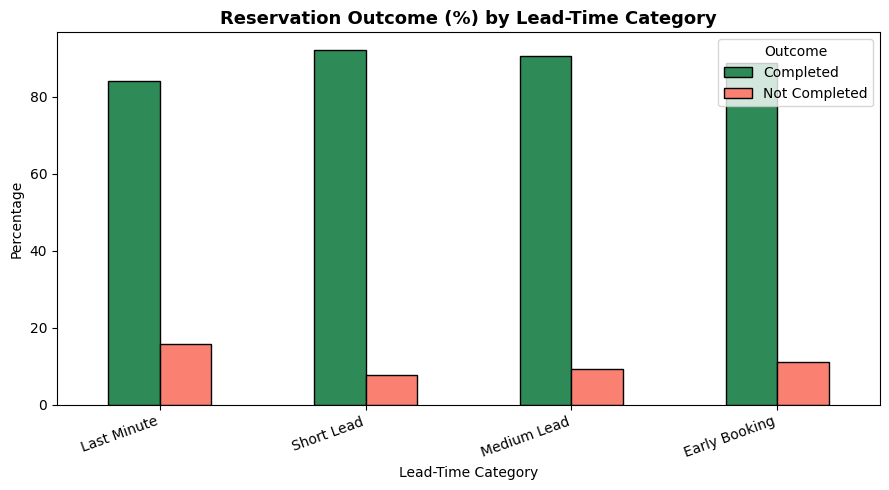


INTERPRETATION (Chart 3):
There is a clear relationship between how far in advance a reservation is
made and the likelihood of completion. Last-minute bookings typically show
higher Not-Completed rates, while Early Booking tends to have higher
completion. This evidence supports policies that encourage earlier booking
or require extra confirmation for short-lead reservations.



In [ ]:
# Q3
# Safe fallbacks if cells were run out of order
if 'Lead_Time_Category' not in df.columns and 'Days_Before_Event' in df.columns:
    def lead_time_cat(days):
        if pd.isna(days): return np.nan
        if days <= 2: return 'Last Minute'
        elif days <= 7: return 'Short Lead'
        elif days <= 14: return 'Medium Lead'
        else: return 'Early Booking'
    df['Lead_Time_Category'] = df['Days_Before_Event'].apply(lead_time_cat)

if 'Reservation_Outcome' not in df.columns and 'Usage_Status' in df.columns:
    df['Reservation_Outcome'] = df['Usage_Status'].apply(
        lambda s: 'Completed' if s == 'Used' else 'Not Completed'
    )

lead_outcome = pd.crosstab(df['Lead_Time_Category'], df['Reservation_Outcome'],
                           normalize='index') * 100
order = ['Last Minute', 'Short Lead', 'Medium Lead', 'Early Booking']
lead_outcome = lead_outcome.reindex([c for c in order if c in lead_outcome.index])

print("=" * 60)
print("Q3: RESERVATION OUTCOME % BY LEAD-TIME CATEGORY")
print("(Denominator = total reservations within each Lead_Time_Category)")
print("=" * 60)
print(lead_outcome.round(2))

plt.figure(figsize=(9, 5))
lead_outcome.plot(kind='bar', color=['seagreen', 'salmon'],
                  edgecolor='black', ax=plt.gca())
plt.title('Reservation Outcome (%) by Lead-Time Category',
          fontsize=13, fontweight='bold')
plt.xlabel('Lead-Time Category')
plt.ylabel('Percentage')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Outcome')
plt.tight_layout()
plt.show()

print("""
INTERPRETATION (Chart 3):
There is a clear relationship between how far in advance a reservation is
made and the likelihood of completion. Last-minute bookings typically show
higher Not-Completed rates, while Early Booking tends to have higher
completion. This evidence supports policies that encourage earlier booking
or require extra confirmation for short-lead reservations.
""")

PREDICTORS USED (all known at booking time):
['Facility_Type', 'User_Type', 'Days_Before_Event', 'Participants', 'Duration_Hours']

LEAKAGE AVOIDANCE:
Excluded because they are only known AFTER the outcome:
  • Usage_Status
  • Actual_Attendance
  • Cancellation_Days_Before
  • Attendance_Ratio
  • Reservation_Outcome

Modeling dataset shape: (400, 6)
Class distribution:
Reservation_Outcome
Completed        359
Not Completed     41
Name: count, dtype: int64
Encoded Facility_Type: {'Auditorium': np.int64(0), 'Classroom': np.int64(1), 'Conference Room': np.int64(2), 'Gymnasium': np.int64(3), 'Laboratory': np.int64(4), 'Multimedia Room': np.int64(5)}
Encoded User_Type: {'Faculty': np.int64(0), 'Organization': np.int64(1), 'Staff': np.int64(2), 'Student': np.int64(3)}

Target encoding: {'Completed': np.int64(0), 'Not Completed': np.int64(1)}

Train size: 320, Test size: 80

MODEL EVALUATION RESULTS
Accuracy : 0.9000
Precision: 0.8100
Recall   : 0.9000
F1-score : 0.8526

Classification Repo

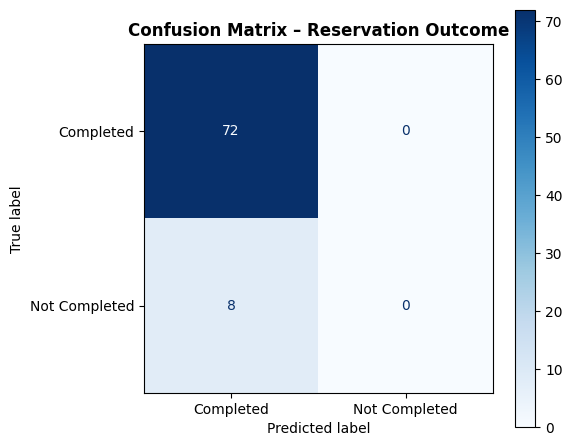


FEATURE IMPORTANCES:
Participants         0.4415
Facility_Type        0.3085
Days_Before_Event    0.1624
Duration_Hours       0.0876
User_Type            0.0000
dtype: float64

Three most influential predictors:
  1. Participants (importance = 0.4415)
  2. Facility_Type (importance = 0.3085)
  3. Days_Before_Event (importance = 0.1624)


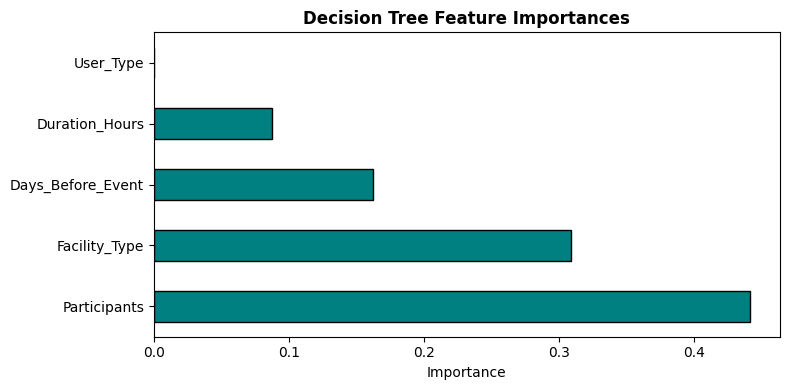

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)

# Predictors available at booking time only (NO LEAKAGE)
predictors = ['Facility_Type', 'User_Category', 'Lead_Time_Days',
              'Participants', 'Reservation_Method']
if 'Duration_Hours' in df.columns:
    predictors.append('Duration_Hours')

print("PREDICTORS USED (all known at booking time):")
print(predictors)
print("""
LEAKAGE AVOIDANCE:
Excluded because they are only known AFTER the outcome:
  • Usage_Status
  • Actual_Attendance
  • Cancellation_Days_Before
  • Attendance_Ratio
  • Reservation_Outcome
""")

model_df = df[predictors + ['Reservation_Outcome']].dropna().copy()
print(f"Modeling dataset shape: {model_df.shape}")
print(f"Class distribution:\n{model_df['Reservation_Outcome'].value_counts()}")

# Encode categoricals
cat_cols = [c for c in ['Facility_Type', 'User_Category', 'Reservation_Method'] if c in predictors]
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    model_df[col] = le.fit_transform(model_df[col].astype(str))
    label_encoders[col] = le
    print(f"Encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

target_le = LabelEncoder()
y = target_le.fit_transform(model_df['Reservation_Outcome'])
print(f"\nTarget encoding: {dict(zip(target_le.classes_, target_le.transform(target_le.classes_)))}")

X = model_df[predictors]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"\nTrain size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

clf = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1   = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("\n" + "=" * 60)
print("MODEL EVALUATION RESULTS")
print("=" * 60)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=target_le.classes_, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=target_le.classes_)
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Reservation Outcome', fontweight='bold')
plt.tight_layout()
plt.show()

importances = pd.Series(clf.feature_importances_, index=predictors).sort_values(ascending=False)
print("\nFEATURE IMPORTANCES:")
print(importances.round(4))
print("\nThree most influential predictors:")
for i, (feat, imp) in enumerate(importances.head(3).items(), 1):
    print(f"  {i}. {feat} (importance = {imp:.4f})")

plt.figure(figsize=(8, 4))
importances.plot(kind='barh', color='teal', edgecolor='black')
plt.title('Decision Tree Feature Importances', fontweight='bold')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()